# Completed Task 2: experiment and reproduction notebook

Author: Alaa Boghdady. The original baseline code/output cells below are retained. The final sections embed the offline VCTK inputs and extension code. Those extension cells are supplied for reproduction and are not falsely marked executed in this copy. Actual extension evidence is in `results/accent_all_trials.csv`, `results/accent_per_sample.csv`, and the recorded-results table below. Earlier baseline accent warnings describe the baseline stage only; the final 16-input study includes the extension.


# Task 2 - Qwen3-ASR-1.7B: reproducible speech recognition experiment
**Alaa Boghdady | Cellula AI Internship | Week 8**

This notebook contains an experiment, not measured results. Run it on a Colab GPU to create real evidence.

**بداية سريعة:** من Runtime اختاري Change runtime type ثم T4 GPU أو أي GPU متاح. شغّلي الخلايا بالترتيب. في النهاية نزّلي النتائج، واحفظي نسخة النوتبوك بعد التشغيل.

The assignment requires architecture research AND real inference with varied speakers, accents, conditions and durations. Public LibriSpeech samples below provide reference text and speaker diversity; their accents are **not verified**. Add consented/public samples with known different accents in section 5 before claiming the accent requirement is complete. No training/fine-tuning is needed.

Official implementation: https://github.com/QwenLM/Qwen3-ASR

Model: https://huggingface.co/Qwen/Qwen3-ASR-1.7B

Research: https://arxiv.org/abs/2601.21337

Dataset: https://huggingface.co/datasets/openslr/librispeech_asr (CC BY 4.0; derived from LibriSpeech/OpenSLR).

## 1. Install dependencies
Use the official `qwen-asr` transformers backend. FlashAttention and vLLM are optional and are not required here. This cell does not reinstall PyTorch, which Colab supplies. If Colab asks for a session restart after installation, restart it and continue at section 2. Package versions are recorded in the exported evidence.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'qwen-asr', 'datasets', 'soundfile', 'librosa', 'jiwer', 'pandas', 'matplotlib'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'qwen-asr', 'datasets', 'soundfile', 'librosa', 'jiwer', 'pandas', 'matplotlib'], returncode=0)

## 2. Check the runtime and create output folders

In [2]:
import os, io, json, time, platform, random, unicodedata, importlib.metadata as metadata
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import soundfile as sf
import librosa
import jiwer
from datasets import load_dataset, Audio
from IPython.display import display, Audio as AudioPlayer

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = Path('/content/task2_qwen3_asr') if Path('/content').exists() else Path.cwd() / 'task2_qwen3_asr'
SAMPLES = ROOT / 'samples'; RESULTS = ROOT / 'results'
SAMPLES.mkdir(parents=True, exist_ok=True); RESULTS.mkdir(parents=True, exist_ok=True)
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU found. In Colab choose Runtime > Change runtime type > GPU, then reconnect.')
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
environment = {
    'python': sys.version, 'platform': platform.platform(), 'torch': torch.__version__,
    'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0),
    'gpu_total_gib': torch.cuda.get_device_properties(0).total_memory / 1024**3,
    'dtype': str(DTYPE), 'seed': SEED,
    'packages': {p: metadata.version(p) for p in ['qwen-asr','transformers','datasets','soundfile','librosa','jiwer','pandas']},
}
print(json.dumps(environment, indent=2))


{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.14.1+cu130",
  "cuda": "13.0",
  "gpu": "Tesla T4",
  "gpu_total_gib": 14.56317138671875,
  "dtype": "torch.bfloat16",
  "seed": 42,
  "packages": {
    "qwen-asr": "0.0.6",
    "transformers": "4.57.6",
    "datasets": "4.8.5",
    "soundfile": "0.14.0",
    "librosa": "0.11.0",
    "jiwer": "4.0.0",
    "pandas": "2.2.3"
  }
}


## 3. Load the exact assigned model
Batch size 1 limits memory pressure. FP16 is selected on GPUs without BF16 support. Downloads require internet and several GB of disk space. Cold loading time is separate from transcription time. This notebook never substitutes the 0.6B checkpoint for the required 1.7B model.

In [3]:
from huggingface_hub import model_info
from qwen_asr import Qwen3ASRModel
MODEL_ID = 'Qwen/Qwen3-ASR-1.7B'
MODEL_REVISION = model_info(MODEL_ID).sha
torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
load_start = time.perf_counter()
model = Qwen3ASRModel.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE, device_map='cuda:0',
    max_inference_batch_size=1, max_new_tokens=512,
)
torch.cuda.synchronize()
environment.update({'model_id': MODEL_ID, 'model_revision': MODEL_REVISION,
                    'model_load_s': time.perf_counter()-load_start,
                    'load_peak_allocated_gib': torch.cuda.max_memory_allocated()/1024**3,
                    'max_new_tokens': 512, 'language_hint': None})
print('Loaded:', MODEL_ID, '\nRevision:', MODEL_REVISION)
print('Load seconds:', round(environment['model_load_s'], 2))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.22G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/478M [00:00<?, ?B/s]

... (5 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

Loaded: Qwen/Qwen3-ASR-1.7B 
Revision: 7278e1e70fe206f11671096ffdd38061171dd6e5
Load seconds: 85.65


## 4. Prepare public reference-backed audio
Stream a small `test`/`clean` subset and select one utterance per speaker. Files are decoded with SoundFile so the experiment does not depend on TorchCodec. The default is six speakers, 2-30 seconds each. Speaker count and duration range are checked, not assumed. If the stream cannot provide six within 800 records, the notebook stops clearly; adjust selection or use custom samples.

For each clean utterance, create a paired noisy version at 10 dB SNR. Noise is a **controlled synthetic perturbation**, not a real noisy recording. The same reference remains valid because duration and word content do not change. Accent metadata remains `unknown`.

In [4]:
def mono_resample(audio, sr):
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2: audio = audio.mean(axis=1)
    if sr != 16000: audio = librosa.resample(audio, orig_sr=sr, target_sr=16000)
    return np.asarray(audio, dtype=np.float32)

stream = load_dataset('openslr/librispeech_asr', 'clean', split='test', streaming=True)
stream = stream.cast_column('audio', Audio(decode=False))
records = []; used_speakers = set()
for index, item in enumerate(stream):
    if index >= 800: break
    speaker = str(item['speaker_id'])
    if speaker in used_speakers: continue
    raw = item['audio']
    if raw.get('bytes') is not None:
        audio, sr = sf.read(io.BytesIO(raw['bytes']), dtype='float32')
    else:
        audio, sr = sf.read(raw['path'], dtype='float32')
    audio = mono_resample(audio, sr); duration = len(audio)/16000
    if not 2 <= duration <= 30: continue
    sample_id = str(item['id'])
    filename = SAMPLES / (sample_id + '_clean.wav')
    sf.write(filename, audio, 16000, subtype='PCM_16')
    records.append({'sample_id': sample_id+'_clean', 'pair_id': sample_id,
                    'path': str(filename), 'reference': item['text'],
                    'speaker': speaker, 'accent': 'unknown', 'language': 'English',
                    'condition': 'clean', 'snr_db': None,
                    'source': 'openslr/librispeech_asr clean/test', 'license': 'CC BY 4.0'})
    used_speakers.add(speaker)
    if len(used_speakers) == 6: break
if len(used_speakers) < 6:
    raise RuntimeError(f'Only {len(used_speakers)} speakers found. Increase the scan limit or supply custom samples.')

rng = np.random.default_rng(SEED)
for row in list(records):
    audio, sr = sf.read(row['path'], dtype='float32')
    noise = rng.normal(size=audio.shape).astype(np.float32)
    signal_rms = np.sqrt(np.mean(audio**2)); noise_rms = np.sqrt(np.mean(noise**2))
    noisy = audio + noise * (signal_rms / (10**(10/20) * max(noise_rms, 1e-12)))
    # Peak scaling avoids clipping without changing the signal-to-noise ratio.
    noisy = noisy / max(1.0, float(np.max(np.abs(noisy))))
    filename = SAMPLES / (row['pair_id'] + '_noise10.wav')
    sf.write(filename, noisy, sr, subtype='PCM_16')
    records.append({**row, 'sample_id': row['pair_id']+'_noise10', 'path': str(filename),
                    'condition': 'synthetic_white_noise', 'snr_db': 10})
print('Prepared', len(records), 'files from', len(used_speakers), 'speakers.')
display(pd.DataFrame(records)[['sample_id','speaker','accent','condition']])


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Prepared 12 files from 6 speakers.


,sample_id,speaker,accent,condition
0,6930-75918-0000_clean,6930,unknown,clean
1,1320-122617-0000_clean,1320,unknown,clean
2,5639-40744-0000_clean,5639,unknown,clean
3,260-123440-0000_clean,260,unknown,clean
4,7729-102255-0000_clean,7729,unknown,clean
5,2094-142345-0000_clean,2094,unknown,clean
6,6930-75918-0000_noise10,6930,unknown,synthetic_white_noise
7,1320-122617-0000_noise10,1320,unknown,synthetic_white_noise
8,5639-40744-0000_noise10,5639,unknown,synthetic_white_noise
9,260-123440-0000_noise10,260,unknown,synthetic_white_noise


## 5. Add samples with known accents (needed for full assignment coverage)
Use only public/licensed or consented audio. Add at least two **known different accents**, with separate manually verified transcripts and speaker IDs. Do not infer accents from names or dataset membership. You may use Egyptian-accented English and another verified English accent, or clearly labelled Arabic varieties, if available.

On your computer create `custom_manifest.csv` with columns:
`sample_id,filename,reference,speaker,accent,language,condition,source,license`

Upload the CSV and its audio files together. `filename` must match the upload name. Write the reference **before** viewing the model transcription. For non-English text, the same Unicode normalization policy below is applied; no special Arabic letter folding is performed. Leave `ADD_CUSTOM = False` for an initial baseline run, then rerun this cell and sections 6-9 after adding real accent samples.

In [5]:
ADD_CUSTOM = False  # Set True when your CSV and consented/public audio files are ready.
if ADD_CUSTOM:
    from google.colab import files
    uploaded = files.upload()
    if 'custom_manifest.csv' not in uploaded:
        raise ValueError('Upload custom_manifest.csv and all referenced audio files.')
    custom = pd.read_csv(io.BytesIO(uploaded['custom_manifest.csv']), keep_default_na=False)
    required = {'sample_id','filename','reference','speaker','accent','language','condition','source','license'}
    if not required.issubset(custom.columns):
        raise ValueError('Missing CSV columns: '+str(required-set(custom.columns)))
    records = [r for r in records if not r.get('is_custom')]
    for row in custom.to_dict('records'):
        if any(not str(row[k]).strip() for k in required): raise ValueError('Every custom field must be filled.')
        filename = str(row['filename'])
        if filename not in uploaded: raise ValueError('Missing uploaded audio: '+filename)
        audio, sr = sf.read(io.BytesIO(uploaded[filename]), dtype='float32')
        audio = mono_resample(audio, sr)
        if not 0 < len(audio)/16000 <= 60: raise ValueError('Use 0-60 second custom clips.')
        sid = str(row['sample_id'])
        if not sid.replace('_','').replace('-','').isalnum(): raise ValueError('Use simple unique sample IDs.')
        path = SAMPLES / ('custom_'+sid+'.wav'); sf.write(path, audio, 16000, subtype='PCM_16')
        records.append({**row, 'sample_id':'custom_'+sid, 'path':str(path),
                        'pair_id':'custom_'+sid, 'snr_db':None, 'is_custom':True})
ids = [r['sample_id'] for r in records]
assert len(ids) == len(set(ids)), 'Duplicate sample IDs'
manifest = pd.DataFrame(records)
manifest['duration_s'] = [sf.info(p).duration for p in manifest.path]
manifest.to_csv(RESULTS/'manifest.csv', index=False)
known_accents = {r['accent'].casefold().strip() for r in records if r['accent'].casefold().strip() not in {'unknown','unspecified','n/a'}}
environment['verified_accent_labels'] = sorted(known_accents)
environment['accent_coverage_complete'] = len(known_accents) >= 2
print('Known accents:', sorted(known_accents))
print('Accent coverage complete:', environment['accent_coverage_complete'])
print('Duration range:', round(manifest.duration_s.min(),2), '-', round(manifest.duration_s.max(),2),'seconds')
if not environment['accent_coverage_complete']:
    print('BASELINE ONLY: add verified accent samples before claiming full assignment coverage.')
display(manifest[['sample_id','duration_s','speaker','accent','condition']])
display(AudioPlayer(filename=records[0]['path']))


Known accents: []
Accent coverage complete: False
Duration range: 2.17 - 22.57 seconds
BASELINE ONLY: add verified accent samples before claiming full assignment coverage.


,sample_id,duration_s,speaker,accent,condition
0,6930-75918-0000_clean,3.505,6930,unknown,clean
1,1320-122617-0000_clean,7.835,1320,unknown,clean
2,5639-40744-0000_clean,15.770,5639,unknown,clean
3,260-123440-0000_clean,2.165,260,unknown,clean
4,7729-102255-0000_clean,3.285,7729,unknown,clean
5,2094-142345-0000_clean,22.570,2094,unknown,clean
6,6930-75918-0000_noise10,3.505,6930,unknown,synthetic_white_noise
7,1320-122617-0000_noise10,7.835,1320,unknown,synthetic_white_noise
8,5639-40744-0000_noise10,15.770,5639,unknown,synthetic_white_noise
9,260-123440-0000_noise10,2.165,260,unknown,synthetic_white_noise


## 6. Define and check evaluation metrics
WER = (substitutions + deletions + insertions) / reference words. CER is the analogous character metric. Rates can exceed 100% when insertions are numerous. Empty references are rejected here.

Report raw and normalized results. Normalization uses Unicode NFC, casefolding, replaces punctuation/symbols with spaces, then collapses whitespace. It does not remove diacritics or fold Arabic letters. CER includes spaces after this normalization. Corpus scores use aggregate edit counts (via JiWER), not an unweighted mean of per-file rates.

In [6]:
def normalize(text):
    text = unicodedata.normalize('NFC', str(text)).casefold()
    text = ''.join(' ' if unicodedata.category(ch)[0] in {'P','S'} else ch for ch in text)
    return ' '.join(text.split())

assert normalize('Hello, WORLD!') == 'hello world'
assert jiwer.wer('a b c','a x c') == 1/3
assert jiwer.wer('a b','a') == 0.5
assert jiwer.wer('a b','a b c') == 0.5
assert jiwer.cer('cat','cut') == 1/3
if any(not normalize(r['reference']) for r in records):
    raise ValueError('Every recording needs a non-empty ground-truth transcript.')
print('Metric sanity checks passed.')


Metric sanity checks passed.


## 7. Run actual inference and collect measurements
One unmeasured warm-up precedes all samples. Timing includes the transcribe call and GPU synchronization, but excludes installation, weight download and model loading. Each sample is repeated three times; retain all runs and use the median time. Disk read is done before timing; internal preprocessing remains included. Memory is peak PyTorch-allocated GPU memory for the entire loaded process, not total device usage. RTF = processing seconds / audio seconds. No throughput guarantee is made.

In [7]:
REPEATS = 3
warm_audio, warm_sr = sf.read(records[0]['path'], dtype='float32')
with torch.inference_mode():
    _ = model.transcribe(audio=(warm_audio, warm_sr), language=None)
torch.cuda.synchronize()

rows = []; trial_rows = []
for row in records:
    audio, sr = sf.read(row['path'], dtype='float32')
    trials = []
    for trial in range(REPEATS):
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        with torch.inference_mode():
            result = model.transcribe(audio=(audio, sr), language=None)[0]
        torch.cuda.synchronize()
        elapsed = time.perf_counter()-start
        measurement = {'sample_id':row['sample_id'], 'trial':trial+1,
                       'processing_s':elapsed, 'prediction':result.text,
                       'detected_language':result.language,
                       'peak_allocated_gib':torch.cuda.max_memory_allocated()/1024**3}
        trials.append(measurement); trial_rows.append(measurement)
    prediction = trials[0]['prediction']
    ref, hyp = normalize(row['reference']), normalize(prediction)
    word = jiwer.process_words(ref,hyp); char = jiwer.process_characters(ref,hyp)
    duration = len(audio)/sr; median_time = float(np.median([t['processing_s'] for t in trials]))
    rows.append({**row, 'duration_s':duration, 'prediction':prediction,
                 'detected_language':trials[0]['detected_language'],
                 'reference_normalized':ref, 'prediction_normalized':hyp,
                 'raw_wer':jiwer.wer(row['reference'],prediction),
                 'raw_cer':jiwer.cer(row['reference'],prediction),
                 'wer':word.wer, 'cer':char.cer,
                 'substitutions':word.substitutions, 'deletions':word.deletions, 'insertions':word.insertions,
                 'reference_words':len(ref.split()),
                 'median_processing_s':median_time, 'rtf':median_time/duration,
                 'peak_allocated_gib':max(t['peak_allocated_gib'] for t in trials),
                 'repeat_transcripts_identical':len({t['prediction'] for t in trials})==1})
    # Checkpoint after each clip, so a disconnected runtime need not lose all evidence.
    pd.DataFrame(rows).to_csv(RESULTS/'per_sample.csv', index=False)
    pd.DataFrame(trial_rows).to_csv(RESULTS/'all_trials.csv', index=False)
    print(row['sample_id'], '| WER:', round(100*word.wer,2), '% | RTF:', round(median_time/duration,3))
df = pd.DataFrame(rows)
display(df[['sample_id','duration_s','wer','cer','median_processing_s','rtf','peak_allocated_gib']])


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


6930-75918-0000_clean | WER: 0.0 % | RTF: 0.251


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


1320-122617-0000_clean | WER: 0.0 % | RTF: 0.206


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


5639-40744-0000_clean | WER: 4.17 % | RTF: 0.24


... (15 outputs left out)

7729-102255-0000_noise10 | WER: 0.0 % | RTF: 0.21


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


2094-142345-0000_noise10 | WER: 4.08 % | RTF: 0.176


,sample_id,duration_s,wer,cer,median_processing_s,rtf,peak_allocated_gib
0,6930-75918-0000_clean,3.505,0.000000,0.000000,0.879796,0.251012,3.834349
1,1320-122617-0000_clean,7.835,0.000000,0.000000,1.617108,0.206395,3.856927
2,5639-40744-0000_clean,15.770,0.041667,0.015748,3.780530,0.239729,3.903008
3,260-123440-0000_clean,2.165,0.000000,0.000000,0.675866,0.312178,3.827300
4,7729-102255-0000_clean,3.285,0.000000,0.000000,0.690519,0.210204,3.833140
5,2094-142345-0000_clean,22.570,0.040816,0.003571,3.801026,0.168411,3.944597
6,6930-75918-0000_noise10,3.505,0.000000,0.000000,0.937489,0.267472,3.834349
7,1320-122617-0000_noise10,7.835,0.000000,0.000000,1.614687,0.206086,3.856927
8,5639-40744-0000_noise10,15.770,0.041667,0.011811,3.640697,0.230862,3.903008
9,260-123440-0000_noise10,2.165,0.000000,0.000000,0.678725,0.313499,3.827300


## 8. Summarize and plot actual results

,group,n,corpus_wer,corpus_cer,audio_total_s,median_latency_s,aggregate_rtf,peak_allocated_gib
0,all_samples,12,0.028986,0.005718,110.26,1.276088,0.208317,3.944597
1,clean,6,0.028986,0.006353,55.13,1.248452,0.207597,3.944597
2,synthetic_white_noise,6,0.028986,0.005083,55.13,1.276088,0.209036,3.944597


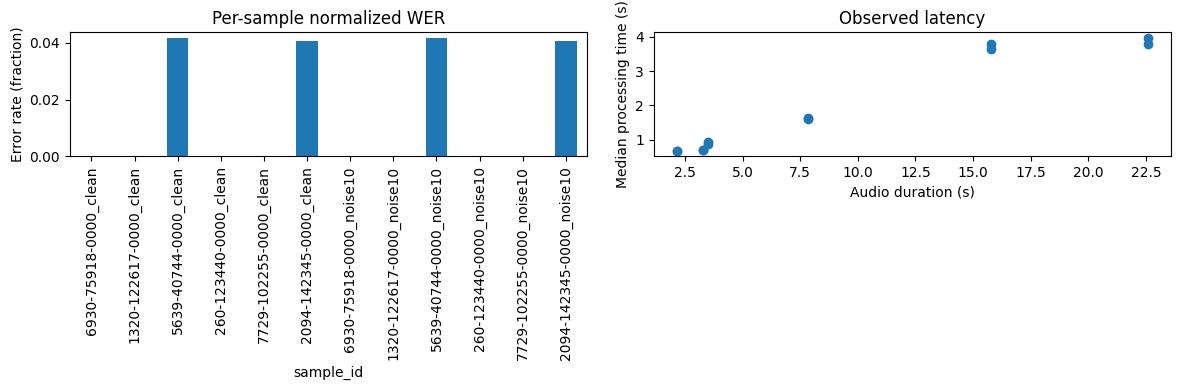

Full accent coverage: False
Small-sample experiment only; paired noisy clips are not independent speakers.


In [8]:
def summarize(group, label):
    refs = group.reference_normalized.tolist(); hyps = group.prediction_normalized.tolist()
    return {'group':label, 'n':len(group),
            'corpus_wer':jiwer.wer(refs,hyps), 'corpus_cer':jiwer.cer(refs,hyps),
            'audio_total_s':float(group.duration_s.sum()),
            'median_latency_s':float(group.median_processing_s.median()),
            'aggregate_rtf':float(group.median_processing_s.sum()/group.duration_s.sum()),
            'peak_allocated_gib':float(group.peak_allocated_gib.max())}
summary = pd.DataFrame([summarize(df,'all_samples')] +
                       [summarize(g,str(k)) for k,g in df.groupby('condition')])
summary.to_csv(RESULTS/'summary.csv',index=False)
environment.update({'sample_count':len(df), 'unique_speakers':int(df.speaker.nunique()),
                    'repeats':REPEATS, 'normalization':'NFC, casefold, punctuation/symbol -> spaces, collapse whitespace; CER includes spaces',
                    'measurement_note':'latency excludes load/download; warmup excluded; peak allocated GPU process memory'})
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
display(summary)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(12,4))
df.plot.bar(x='sample_id',y='wer',ax=axes[0],legend=False,title='Per-sample normalized WER')
axes[0].set_ylabel('Error rate (fraction)')
axes[1].scatter(df.duration_s,df.median_processing_s)
axes[1].set(xlabel='Audio duration (s)',ylabel='Median processing time (s)',title='Observed latency')
fig.tight_layout(); fig.savefig(RESULTS/'results.png',dpi=180,bbox_inches='tight'); plt.show()
subprocess.run([sys.executable,'-m','pip','freeze'],stdout=(RESULTS/'requirements_runtime.txt').open('w'),check=True)
print('Full accent coverage:', environment['accent_coverage_complete'])
print('Small-sample experiment only; paired noisy clips are not independent speakers.')


## 9. Export evidence and finish the report
Download the ZIP, then save the **executed notebook with outputs** using File > Download > Download .ipynb. GitHub must not contain model weights or API secrets. The ZIP includes CSVs, environment/version evidence, plots, public sample audio and references; only share custom recordings when their consent/license allows it. You may remove custom audio before publication while retaining permitted metadata.

For the three-page IEEE report use real tables from `summary.csv` and examples from `per_sample.csv`. Explain errors, accents, noise conditions, duration coverage, hardware and limitations. Scores here are a small study, not the official benchmark. If any inference fails or accents are missing, state that the experiment is incomplete rather than inventing numbers.

In [9]:
import shutil
archive = shutil.make_archive(str(ROOT.parent/'Task_2_Experiment_Results'),'zip',root_dir=ROOT)
print('Evidence bundle:', archive)
from google.colab import files
files.download(archive)


Evidence bundle: /content/Task_2_Experiment_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final extension: dataset-documented English and Scottish accents

The next two cells restore four packaged VCTK files and reproduce the extension using the already-loaded model. Run these after the baseline cells for a fresh end-to-end reproduction. No manual Python-file upload is required. CC BY 4.0 attribution is embedded.


In [ ]:
import base64
from pathlib import Path
OFFLINE_INPUTS = Path('/content/task2_offline_accents')
OFFLINE_INPUTS.mkdir(parents=True, exist_ok=True)
_embedded_inputs = {'ATTRIBUTION.txt': 'Q1NUUiBWQ1RLIENvcnB1cyB2MC45Mi4gSnVuaWNoaSBZYW1hZ2lzaGksIENocmlzdG9waGUgVmVhdXgsIEtpcnN0ZW4gTWFjRG9uYWxkLCAyMDE5LiBVbml2ZXJzaXR5IG9mIEVkaW5idXJnaCBDU1RSLiBET0k6IGh0dHBzOi8vZG9pLm9yZy8xMC43NDg4L2RzLzI2NDUgLiBSZXByZXNlbnRhdGlvbjogaHR0cHM6Ly9odWdnaW5nZmFjZS5jby9kYXRhc2V0cy9rdGgtdG1oL3ZjdGsgLiBDQyBCWSA0LjA6IGh0dHBzOi8vY3JlYXRpdmVjb21tb25zLm9yZy9saWNlbnNlcy9ieS80LjAvIC4gRm91ciBtaWMxIGV4Y2VycHRzIHJlZGlzdHJpYnV0ZWQgdW5tb2RpZmllZDsgdGhlIGV4cGVyaW1lbnQgcmVzYW1wbGVzIHRvIDE2IGtIei4gQWNjZW50IGxhYmVscyBhcmUgZGF0YXNldCBtZXRhZGF0YSwgbm90IGluZGVwZW5kZW50bHkgYXNzZXNzZWQuIE1ldGFkYXRhIGNvbnRhaW5zIHJlZmVyZW5jZSB0ZXh0cyBhbmQgc291cmNlIHJvdyBpbmRpY2VzLiBObyBtb2RlbCBvdXRwdXRzIGFyZSBpbmNsdWRlZC4NCg==', 'metadata.json': 'ew0KICAiMCI6IHsNCiAgICAicm93cyI6IFsNCiAgICAgIHsNCiAgICAgICAgInJvd19pZHgiOiAyLA0KICAgICAgICAicm93Ijogew0KICAgICAgICAgICJzcGVha2VyX2lkIjogInAyMjUiLA0KICAgICAgICAgICJhdWRpbyI6IFsNCiAgICAgICAgICAgIHsNCiAgICAgICAgICAgICAgInNyYyI6ICJwMjI1XzAwMl9taWMxLmZsYWMiLA0KICAgICAgICAgICAgICAidHlwZSI6ICJhdWRpby9mbGFjIg0KICAgICAgICAgICAgfQ0KICAgICAgICAgIF0sDQogICAgICAgICAgImZpbGUiOiAicDIyNV8wMDJfbWljMS5mbGFjIiwNCiAgICAgICAgICAidGV4dCI6ICJBc2sgaGVyIHRvIGJyaW5nIHRoZXNlIHRoaW5ncyB3aXRoIGhlciBmcm9tIHRoZSBzdG9yZS4iLA0KICAgICAgICAgICJ0ZXh0X2lkIjogIjAwMiIsDQogICAgICAgICAgImFnZSI6ICIyMyIsDQogICAgICAgICAgImdlbmRlciI6ICJGIiwNCiAgICAgICAgICAiYWNjZW50IjogIkVuZ2xpc2giLA0KICAgICAgICAgICJyZWdpb24iOiAiU291dGhlcm4gRW5nbGFuZCIsDQogICAgICAgICAgImNvbW1lbnQiOiAiIg0KICAgICAgICB9DQogICAgICB9DQogICAgXSwNCiAgICAiYXVkaW9fc2hhMjU2IjogImRhZGU1ZWU5ODcyN2I1YTQxYWJkYzU1YzI1YmY1OGQ1ZGRkYWU5NDBmMjAwOTI0MTMzOTc0MTM0OTQyYmE0ZmIiDQogIH0sDQogICIzMDAwIjogew0KICAgICJyb3dzIjogWw0KICAgICAgew0KICAgICAgICAicm93X2lkeCI6IDMwMDIsDQogICAgICAgICJyb3ciOiB7DQogICAgICAgICAgInNwZWFrZXJfaWQiOiAicDIyOSIsDQogICAgICAgICAgImF1ZGlvIjogWw0KICAgICAgICAgICAgew0KICAgICAgICAgICAgICAic3JjIjogInAyMjlfMTYyX21pYzEuZmxhYyIsDQogICAgICAgICAgICAgICJ0eXBlIjogImF1ZGlvL2ZsYWMiDQogICAgICAgICAgICB9DQogICAgICAgICAgXSwNCiAgICAgICAgICAiZmlsZSI6ICJwMjI5XzE2Ml9taWMxLmZsYWMiLA0KICAgICAgICAgICJ0ZXh0IjogIkl0J3MgYSBwcm9ibGVtIGJ1dCBpdCBjYW5ub3QgYmVjb21lIGFuIGV4Y3VzZS4iLA0KICAgICAgICAgICJ0ZXh0X2lkIjogIjE2MiIsDQogICAgICAgICAgImFnZSI6ICIyMyIsDQogICAgICAgICAgImdlbmRlciI6ICJGIiwNCiAgICAgICAgICAiYWNjZW50IjogIkVuZ2xpc2giLA0KICAgICAgICAgICJyZWdpb24iOiAiU291dGhlcm4gRW5nbGFuZCIsDQogICAgICAgICAgImNvbW1lbnQiOiAiIg0KICAgICAgICB9DQogICAgICB9DQogICAgXSwNCiAgICAiYXVkaW9fc2hhMjU2IjogImIyMzFiM2Y1MjczMmRlNGNkOTY2M2ZmOTMwZDBlMGVhZDQ5NmU3NGY0OTMwOTAxM2Q2NTc0ZWZjMjNhNzk0NWUiDQogIH0sDQogICI5MDAwIjogew0KICAgICJyb3dzIjogWw0KICAgICAgew0KICAgICAgICAicm93X2lkeCI6IDkwMDAsDQogICAgICAgICJyb3ciOiB7DQogICAgICAgICAgInNwZWFrZXJfaWQiOiAicDIzNyIsDQogICAgICAgICAgImF1ZGlvIjogWw0KICAgICAgICAgICAgew0KICAgICAgICAgICAgICAic3JjIjogInAyMzdfMzA0X21pYzEuZmxhYyIsDQogICAgICAgICAgICAgICJ0eXBlIjogImF1ZGlvL2ZsYWMiDQogICAgICAgICAgICB9DQogICAgICAgICAgXSwNCiAgICAgICAgICAiZmlsZSI6ICJwMjM3XzMwNF9taWMxLmZsYWMiLA0KICAgICAgICAgICJ0ZXh0IjogIlRoZSBtb3ZlIHdhcyB3ZWxjb21lZCBieSB0aGUgUm9tYW4gQ2F0aG9saWMgQ2h1cmNoIGluIFNjb3RsYW5kLiIsDQogICAgICAgICAgInRleHRfaWQiOiAiMzA0IiwNCiAgICAgICAgICAiYWdlIjogIjIyIiwNCiAgICAgICAgICAiZ2VuZGVyIjogIk0iLA0KICAgICAgICAgICJhY2NlbnQiOiAiU2NvdHRpc2giLA0KICAgICAgICAgICJyZWdpb24iOiAiRmlmZSIsDQogICAgICAgICAgImNvbW1lbnQiOiAiIg0KICAgICAgICB9DQogICAgICB9DQogICAgXSwNCiAgICAiYXVkaW9fc2hhMjU2IjogImViMzVlNjJlNTE0M2Y2YzM0ZGQ5ZDIyZDVkMjE5NDM3M2Y3NzgzMGE2Y2EwZGUzYWMxNGY1ZDcwMTQwNDc2MWQiDQogIH0sDQogICIxMjAwMCI6IHsNCiAgICAicm93cyI6IFsNCiAgICAgIHsNCiAgICAgICAgInJvd19pZHgiOiAxMjAwMCwNCiAgICAgICAgInJvdyI6IHsNCiAgICAgICAgICAic3BlYWtlcl9pZCI6ICJwMjQxIiwNCiAgICAgICAgICAiYXVkaW8iOiBbDQogICAgICAgICAgICB7DQogICAgICAgICAgICAgICJzcmMiOiAicDI0MV8xMzBfbWljMS5mbGFjIiwNCiAgICAgICAgICAgICAgInR5cGUiOiAiYXVkaW8vZmxhYyINCiAgICAgICAgICAgIH0NCiAgICAgICAgICBdLA0KICAgICAgICAgICJmaWxlIjogInAyNDFfMTMwX21pYzEuZmxhYyIsDQogICAgICAgICAgInRleHQiOiAiVGhlIHRhc2sgZm9yY2UgY29udGludWVzIHRvIGJlIGluIGRpc2N1c3Npb24gd2l0aCBib3RoIGNvbXBhbmllcy4iLA0KICAgICAgICAgICJ0ZXh0X2lkIjogIjEzMCIsDQogICAgICAgICAgImFnZSI6ICIyMSIsDQogICAgICAgICAgImdlbmRlciI6ICJNIiwNCiAgICAgICAgICAiYWNjZW50IjogIlNjb3R0aXNoIiwNCiAgICAgICAgICAicmVnaW9uIjogIlBlcnRoIiwNCiAgICAgICAgICAiY29tbWVudCI6ICIiDQogICAgICAgIH0NCiAgICAgIH0NCiAgICBdLA0KICAgICJhdWRpb19zaGEyNTYiOiAiZTA2NjA3YTIwYmY2ZDNmNzNjYjU5NmJmZmUxZDYxNWM1ZTExNjkyNDA5YzY1NGEzN2NlZjMzMThhMDgxYTc5NiINCiAgfQ0KfQ==', 'p225_002_mic1.flac': '...', 'p229_162_mic1.flac': '...', 'p237_304_mic1.flac': '...', 'p241_130_mic1.flac': '...'}
for _name, _encoded in _embedded_inputs.items():
    (OFFLINE_INPUTS / _name).write_bytes(base64.b64decode(_encoded))
print('Offline VCTK inputs restored; no dataset-row API calls required.')


In [ ]:
"""Paste this ENTIRE file into one final cell of the already-run Colab notebook.
Uses the loaded Qwen3-ASR model. Does not rerun the 12 baseline recordings.
Adds four VCTK speakers with dataset-labelled English/Scottish accents.
"""
import io, json, time, hashlib, shutil, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
from IPython.display import display

if 'model' not in globals():
    raise RuntimeError('Open the ORIGINAL notebook/session where the model is loaded. If it disconnected, rerun only the install, environment and model-loading cells first, then run this cell.')
ROOT = Path('/content/task2_qwen3_asr')
RESULTS = ROOT / 'results'; SAMPLES = ROOT / 'samples'
if not (RESULTS/'per_sample.csv').exists():
    raise RuntimeError('Baseline results are missing from this session. Upload and extract your saved Task_2_Experiment_Results.zip into /content/task2_qwen3_asr first. Do not fabricate baseline results.')

def normalize(text):
    text = unicodedata.normalize('NFC',str(text)).casefold()
    return ' '.join(''.join(' ' if unicodedata.category(ch)[0] in {'P','S'} else ch for ch in text).split())

OFFLINE_INPUTS = Path('/content/task2_offline_accents')
def get_rows(offset):
    return json.loads((OFFLINE_INPUTS/'metadata.json').read_text())[str(offset)]

# These offsets were inspected during preparation: p225/p229 English and
# p237/p241 Scottish. Every label and speaker is checked again at run time.
targets = [(0,'English'),(3000,'English'),(9000,'Scottish'),(12000,'Scottish')]
selected = []; used_speakers = set()
for offset, expected_accent in targets:
    page = get_rows(offset)
    for entry in page['rows']:
        row = entry['row']
        if row.get('accent') != expected_accent: continue
        if row['speaker_id'] in used_speakers: continue
        if 'mic1' not in row.get('file',''): continue
        if len(normalize(row['text']).split()) < 8: continue
        audio, sr = sf.read(OFFLINE_INPUTS / row['audio'][0]['src'],dtype='float32')
        if audio.ndim == 2: audio = audio.mean(axis=1)
        if sr != 16000: audio = librosa.resample(audio,orig_sr=sr,target_sr=16000)
        duration = len(audio)/16000
        if not 1 <= duration <= 30: continue
        sample_id = f"vctk_{row['speaker_id']}_{row['text_id']}_mic1"
        path = SAMPLES/(sample_id+'.wav'); SAMPLES.mkdir(parents=True,exist_ok=True)
        sf.write(path,audio,16000,subtype='PCM_16')
        selected.append({'sample_id':sample_id,'pair_id':sample_id,'path':str(path),
                         'reference':row['text'],'speaker':row['speaker_id'],
                         'accent':row['accent'],'region':row.get('region',''),
                         'accent_label_source':'VCTK speaker metadata via kth-tmh/vctk; not independently assessed',
                         'language':'English','condition':'vctk_accent_read_speech','snr_db':None,
                         'source':'https://huggingface.co/datasets/kth-tmh/vctk',
                         'source_row_index':entry['row_idx'],'license':'CC BY 4.0',
                         'duration_s':duration,'audio_sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
        used_speakers.add(row['speaker_id']); break
    else:
        raise RuntimeError(f'No matching sample at offset {offset}. Dataset may have changed; send this error so selection can be updated.')
assert len(selected)==4 and len(used_speakers)==4
assert {r['accent'] for r in selected}=={'English','Scottish'}
display(pd.DataFrame(selected)[['sample_id','accent','region','duration_s','reference']])

# Save sources BEFORE inference. No reference text is derived from predictions.
pd.DataFrame(selected).to_csv(RESULTS/'accent_manifest.csv',index=False)
warm,sr = sf.read(selected[0]['path'],dtype='float32')
with torch.inference_mode(): model.transcribe(audio=(warm,sr),language=None)
torch.cuda.synchronize()
new_rows = []; new_trials = []
for row in selected:
    audio,sr = sf.read(row['path'],dtype='float32'); trials=[]
    for trial in range(3):
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        with torch.inference_mode(): result = model.transcribe(audio=(audio,sr),language=None)[0]
        torch.cuda.synchronize()
        item={'sample_id':row['sample_id'],'trial':trial+1,'processing_s':time.perf_counter()-start,
              'prediction':result.text,'detected_language':result.language,
              'peak_allocated_gib':torch.cuda.max_memory_allocated()/1024**3}
        trials.append(item); new_trials.append(item)
    prediction=trials[0]['prediction']; ref=normalize(row['reference']); hyp=normalize(prediction)
    words=jiwer.process_words(ref,hyp); chars=jiwer.process_characters(ref,hyp)
    latency=float(np.median([x['processing_s'] for x in trials]))
    new_rows.append({**row,'prediction':prediction,'detected_language':trials[0]['detected_language'],
                     'reference_normalized':ref,'prediction_normalized':hyp,
                     'raw_wer':jiwer.wer(row['reference'],prediction),'raw_cer':jiwer.cer(row['reference'],prediction),
                     'wer':words.wer,'cer':chars.cer,'substitutions':words.substitutions,
                     'deletions':words.deletions,'insertions':words.insertions,'reference_words':len(ref.split()),
                     'median_processing_s':latency,'rtf':latency/row['duration_s'],
                     'peak_allocated_gib':max(x['peak_allocated_gib'] for x in trials),
                     'repeat_transcripts_identical':len({x['prediction'] for x in trials})==1})
    pd.DataFrame(new_rows).to_csv(RESULTS/'accent_per_sample.csv',index=False)
    pd.DataFrame(new_trials).to_csv(RESULTS/'accent_all_trials.csv',index=False)
    print(row['sample_id'],row['accent'],'WER',round(100*words.wer,2),'%')

# Idempotent merge: rerunning this cell replaces prior VCTK extension rows.
baseline=pd.read_csv(RESULTS/'per_sample.csv',keep_default_na=False)
baseline=baseline[~baseline.sample_id.astype(str).str.startswith('vctk_')]
combined=pd.concat([baseline,pd.DataFrame(new_rows)],ignore_index=True)
combined.to_csv(RESULTS/'per_sample.csv',index=False)
old_trials=pd.read_csv(RESULTS/'all_trials.csv',keep_default_na=False)
old_trials=old_trials[~old_trials.sample_id.astype(str).str.startswith('vctk_')]
pd.concat([old_trials,pd.DataFrame(new_trials)],ignore_index=True).to_csv(RESULTS/'all_trials.csv',index=False)
old_manifest=pd.read_csv(RESULTS/'manifest.csv',keep_default_na=False)
old_manifest=old_manifest[~old_manifest.sample_id.astype(str).str.startswith('vctk_')]
pd.concat([old_manifest,pd.DataFrame(selected)],ignore_index=True).to_csv(RESULTS/'manifest.csv',index=False)

def summarize(group,label):
    return {'group':label,'n':len(group),
            'corpus_wer':jiwer.wer(group.reference_normalized.tolist(),group.prediction_normalized.tolist()),
            'corpus_cer':jiwer.cer(group.reference_normalized.tolist(),group.prediction_normalized.tolist()),
            'audio_total_s':float(group.duration_s.sum()),
            'median_latency_s':float(group.median_processing_s.median()),
            'aggregate_rtf':float(group.median_processing_s.sum()/group.duration_s.sum()),
            'peak_allocated_gib':float(group.peak_allocated_gib.max())}
summary=pd.DataFrame([summarize(combined,'all_samples')]+[summarize(g,str(k)) for k,g in combined.groupby('condition')])
summary.to_csv(RESULTS/'summary.csv',index=False)
accent_df=pd.DataFrame(new_rows)
accent_summary=pd.DataFrame([summarize(g,str(k)) for k,g in accent_df.groupby('accent')])
accent_summary.to_csv(RESULTS/'accent_summary.csv',index=False)
environment=json.loads((RESULTS/'environment.json').read_text())
environment.update({'sample_count':len(combined),'unique_speakers':int(combined.speaker.nunique()),
                    'verified_accent_labels':['English','Scottish'],'accent_coverage_complete':True,
                    'accent_label_qualification':'Dataset-documented labels; not independent linguistic assessment',
                    'accent_extension_gpu':torch.cuda.get_device_name(0),'accent_extension_repeats':3,
                    'accent_extension_note':'Four additional VCTK speakers; two per labelled accent. Convenience sample, not a controlled causal accent comparison.'})
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')

# Refresh the plot so it includes all inputs; retain the original evidence CSVs.
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4))
combined.plot.bar(x='sample_id',y='wer',ax=axes[0],legend=False,title='Per-sample normalized WER')
axes[0].set_ylabel('Error rate (fraction)')
axes[1].scatter(combined.duration_s,combined.median_processing_s)
axes[1].set(xlabel='Audio duration (s)',ylabel='Median processing time (s)',title='Observed latency')
fig.tight_layout();fig.savefig(RESULTS/'results.png',dpi=180,bbox_inches='tight');plt.show()
display(summary);display(accent_summary)
print('DONE: 16 inputs, 10 speakers, clean/noise and two dataset-labelled accent groups.')
print('Accent groups have different utterances/speakers. Do not attribute score differences solely to accent.')
archive=shutil.make_archive('/content/Task_2_Completed_Results','zip',root_dir=ROOT)
from google.colab import files
files.download(archive)
print('Now save this EXECUTED notebook using File > Download > Download .ipynb.')


## Recorded final results (imported from uploaded experiment CSVs)

These figures are recorded evidence from the user's completed runs, not claimed execution of the two reproduction cells in this edited notebook.

| Group | Inputs | WER | CER | Aggregate RTF |
|---|---:|---:|---:|---:|
| Clean LibriSpeech | 6 | 2.899% | 0.635% | 0.2076 |
| Noisy LibriSpeech | 6 | 2.899% | 0.508% | 0.2090 |
| VCTK English | 2 | 0.000% | 0.000% | 0.2553 |
| VCTK Scottish | 2 | 0.000% | 0.000% | 0.2791 |
| All inputs | 16 | 2.508% | 0.501% | 0.2156 |

10 speakers; 48 measured trials; 319 normalized reference words; 8 edits. Accent labels are corpus metadata. Only two speakers per accent were tested, so no accent-parity claim is made. Baseline and extension ran in separate Colab sessions; second-session full package metadata was not exported.
